# Homework 1

In [ ]:
#!pip install tqdm spacy --upgrade jupyter ipywidgets networkx pygraphviz

In [ ]:
#!python -m spacy download ru_core_news_sm

In [3]:
from tqdm.notebook import tqdm
import re
import spacy

nlp = spacy.load("ru_core_news_sm")

## Choose a long text, a novel, in Russian or in English

I chose the novel "Childhood" by Leo Tolstoy. I chose a Leo Tolstoy novel specifically because his writing usually contains metaphors, thus, the network graph would include curious occurences

In [4]:
#!wget https://royallib.com/get/txt/tolstoy_lev/detstvo.zip

In [5]:
#!unzip detstvo.zip -d data
#!rm detstvo.zip

In [6]:
with open('data/Толстой Лев. Детство - royallib.com.txt',
          encoding='Windows-1252') as f:
    book = f.read().encode('cp1252').decode('cp1251')
book = book.split('\n\n')

### Clearing the novel

* deleting the technical text like chapter names, empty lines
* deleting special symbols
* deleting Russian translations of the phrases in foreign languages, since the translation was written by an editor and not by the author

In [7]:
lines_to_avoid = [0, 1, 2, 3, 4, 5, 6]
for line in range(len(book)):
    if book[line] == '':
        lines_to_avoid.append(line)
    if book[line][:5] == 'Глава':
        lines_to_avoid.append(line)
        lines_to_avoid.append(line + 1)
    if line >= 722:
        lines_to_avoid.append(line)
clear_book = []
for line in range(len(book)):
    if line not in lines_to_avoid:
        book_line = book[line].replace('\xa0', ' ').replace('\t\t', '').replace('\n', ' ')
        book_line = re.sub('\\[.*\\]', '',  book_line)
        clear_book.append(book_line)

print('Before:', '\n', '\n'.join(book[5:15]), '\n\n',
      'After:', '\n', '\n'.join(clear_book[:5]))

clear_book = ' '.join(clear_book[:100])

Before: 
 Глава I.
УЧИТЕЛЬ КАРЛ ИВАНЫЧ
12 августа 18..., ровно в третий день после дня моего рождения, в который мне минуло десять лет и в который я получил такие чудесные подарки, в семь часов утра — Карл Иваныч разбудил меня, ударив над самой моей головой хлопушкой — из сахарной бумаги на палке — по мухе. Он сделал это так неловко, что задел образок моего ангела, висевший на дубовой спинке кровати, и что убитая муха упала мне прямо на голову. Я высунул нос из-под одеяла, остановил рукою образок, который продолжал качаться, скинул убитую муху на пол и хотя заспанными, но сердитыми глазами окинул Карла Иваныча. Он же, в пестром ваточном халате, подпоясанном поясом из той же материи, в красной вязаной ермолке с кисточкой и в мягких козловых сапогах, продолжал ходить около стен, прицеливаться и хлопать.
«Положим, — думал я, — я маленький, но зачем он тревожит меня? Отчего он не бьет мух около Володи ной постели? вон их сколько! Нет, Володя старше меня; а я меньше всех: оттого он меня и м

# Lemmatize the novel

I am also removing punctuation, stopwords, and digits from the text. The output is a list of lemmas from the entire novel

In [8]:
d = nlp(clear_book)
lemmatized_novel = []
for token in d:
    if token.pos_ != 'PUNCT' and not token.is_stop and not token.is_digit:
        lemmatized_novel.append(token.lemma_)
    #print(token.text, token.lemma_, token.pos_, token.is_stop)
lemmatized_novel

['август',
 'ровно',
 'третий',
 'день',
 'день',
 'рождение',
 'минуть',
 'десять',
 'год',
 'получить',
 'чудесный',
 'подарок',
 'семь',
 'час',
 'утро',
 'карл',
 'иванович',
 'разбудить',
 'ударить',
 'голова',
 'хлопушка',
 'сахарный',
 'бумага',
 'палка',
 'муха',
 'сделать',
 'неловкий',
 'задеть',
 'образок',
 'ангел',
 'висеть',
 'дубовый',
 'спинка',
 'кровать',
 'убить',
 'муха',
 'упасть',
 'прямо',
 'голова',
 'высунуть',
 'нос',
 '-',
 'одеяло',
 'остановить',
 'рукою',
 'образок',
 'продолжать',
 'качаться',
 'скинуть',
 'убить',
 'муха',
 'пол',
 'заспанный',
 'сердитый',
 'глаз',
 'окинуть',
 'карл',
 'иванович',
 'пёстрый',
 'ваточный',
 'халат',
 'подпоясать',
 'пояс',
 'материя',
 'красный',
 'вязаный',
 'ермолка',
 'кисточка',
 'мягкий',
 'козловый',
 'сапог',
 'продолжать',
 'ходить',
 'стена',
 'прицеливаться',
 'хлопать',
 'положить',
 'думать',
 'маленький',
 'тревожить',
 'бить',
 'муха',
 'володи',
 'ной',
 'постель',
 'володя',
 'старший',
 'мучить',
 'дума

Now, I will find the most frequent words in the novel

In [9]:
from collections import Counter

word_counts = Counter(lemmatized_novel)
print(word_counts.most_common(20))

[('иванович', 51), ('карл', 49), ('-', 37), ('говорить', 22), ('сказать', 22), ('рука', 18), ('николай', 16), ('папа', 14), ('книга', 13), ('яков', 13), ('голова', 11), ('сидеть', 11), ('дверь', 11), ('тысяча', 11), ('глаз', 10), ('видеть', 10), ('слеза', 10), ('деньга', 10), ('лицо', 9), ('выражение', 9)]


The verb *сидеть* is interesting to investigate, because it might yield different constructions: preposition phrase government, serial verb constuctions, etc.

# Choose a word and extract all its children (all its syntactic dependencies) and all the children of its children (secondary dependencies).

I am choosing the word *сидеть*

In [ ]:
children_dict = {}
all_dependencies = []
all_pos = []
for token in d:
    if token.lemma_ == 'сидеть':
        for child in token.children:
            all_dependencies.append(child.dep_)
            all_pos.append(child.pos_)
            grandchildren_dict = {}
            for grandchild in child.children:
                all_dependencies.append(grandchild.dep_)
                all_pos.append(grandchild.pos_)
                if grandchild.lemma_.lower() not in grandchildren_dict:
                    grandchildren_dict[grandchild.lemma_.lower()] = {
                        "number_occurences": 1,
                        "dependency": grandchild.dep_,
                        "pos": grandchild.pos_
                    }
                else:
                    # the token-child pair could occur with different dependencies
                    
                    if grandchild.dep_ == grandchildren_dict[grandchild.lemma_.lower()]['dependency']:
                        grandchildren_dict[grandchild.lemma_.lower()]['number_occurences'] += 1
                    else:
                        grandchildren_dict[grandchild.lemma_.lower()] = {
                        "number_occurences": 1,
                        "dependency": grandchild.dep_
                    }
            grandchildren_dict = dict(sorted(grandchildren_dict.items(), key=lambda item: item[1]['dependency']))
            if child.lemma_.lower() not in children_dict:
                children_dict[child.lemma_.lower()] = {
                    "number_occurences": 1,
                    "dependency": child.dep_,
                    'pos': child.pos_,
                    "sentence": token.sent,
                    "grandchildren": grandchildren_dict
                }
            else:
                if child.dep_ == children_dict[child.lemma_.lower()]['dependency']:
                    children_dict[child.lemma_.lower()]['number_occurences'] += 1
                else:
                     children_dict[child.lemma_.lower()] = {
                    "number_occurences": 1,
                    "dependency": child.dep_,
                    "grandchildren": grandchildren_dict
                }

In [ ]:
children_dict = dict(sorted(children_dict.items(), key=lambda item: item[1]['dependency']))

In [19]:
children_dict

{'покойно': {'number_occurences': 1,
  'dependency': 'advmod',
  'pos': 'ADV',
  'sentence': Бывало, стоишь, стоишь в углу, так что колени и спина заболят, и думаешь: «Забыл про меня Карл Иваныч: ему, должно быть, покойно сидеть на мягком кресле и читать свою гидростатику, — а каково мне?» — и начнешь, чтобы напомнить о себе, потихоньку отворять и затворять заслонку или ковырять штукатурку со стены; но если вдруг упадет с шумом слишком большой кусок на землю — право, один страх хуже всякого наказания.,
  'grandchildren': {'ему': {'number_occurences': 1,
    'dependency': 'iobj',
    'pos': 'PRON'},
   'должный': {'number_occurences': 1,
    'dependency': 'parataxis',
    'pos': 'ADJ'}}},
 'всегда': {'number_occurences': 1,
  'dependency': 'advmod',
  'pos': 'ADV',
  'sentence': Бывало, покуда поправляет Карл Иваныч лист с диктовкой, выглянешь в ту сторону, видишь черную головку матушки, чью-нибудь спину и смутно слышишь оттуда говор и смех; так сделается досадно, что нельзя там быть, и

# Create a graph, depicting the result of (3). Set the parameters: what the color and the size of the nodes and the width of the edges stands for. Choose a directed or a non-directed graph. Describe and justify your choices of the parameters.

I chose a directed graph, because syntactic dependency implies a hierarcical relationship.

The color of the nodes will refer to the part-of-speech of the word. The size of the node will not have any meaning.

The color of the edges will signify the type of dependency. The width of the edge will refer to the number of times the word-child pair occurs in the novel: the wider the more often.

In this setup, it will be visually easier to identify governing patterns and their frequency

In [13]:
import networkx as nx
from networkx.algorithms import community
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors


In [20]:
colors_dependencies = {
  'punct': 'black',

  'conj': 'dimgray', # coordination
  'cc': 'silver',

  'aux': 'rosybrown', # fucntion words etc
  'orphan': 'brown',
  'parataxis': 'red',
  'flat:name': 'orangeseed',

  'iobj': 'yellow', # core nominals
  'obj': 'greenyellow',
  'nsubj': 'gold',
  
  'obl': 'aqua', # non-core dependents
  'advmod': 'deepskyblue',
  'mark': 'royalblue',

  'nmod': 'indigo', # nominal dependents
  'appos': 'deeppink',
  'det': 'blue',
  'amod': 'violet',
  'case': 'orchid',
  }

colors_pos = {
    'ADP': 'yellowgreen',
    'ADV': 'yellow',
    'PART': 'brown',
    'VERB': 'gold',
    'PRON': 'wheat',
    'CCONJ': 'violet',
    'AUX': 'turquoise',
    'NOUN': 'tomato',
    'PROPN': 'thistle',
    'ADJ': 'teal',
    'PUNCT': 'tan',
    'NUM': 'steelblue',
    'DET': 'springgreen'}


In [23]:
graph_data = []
edges_dependencies = []
nodes_pos = ['gold']
nodes = []
for key in children_dict:
    graph_data.append((
        'сидеть',
        key,
        children_dict[key]['number_occurences']
    ))
    edges_dependencies.append(colors_dependencies[children_dict[key]['dependency']])
    if key not in nodes:
        nodes_pos.append(colors_pos[children_dict[key]['pos']])
    nodes.append(key)

for key in children_dict:
    for grandchild in children_dict[key]['grandchildren']:
        graph_data.append((
            key,
            grandchild,
            children_dict[key]['grandchildren'][grandchild]['number_occurences']
        ))
        if grandchild not in nodes:
            nodes_pos.append(colors_pos[children_dict[key]['grandchildren'][grandchild]['pos']])
        nodes.append(grandchild)
        edges_dependencies.append(colors_dependencies[children_dict[key]['grandchildren'][grandchild]['dependency']])
        

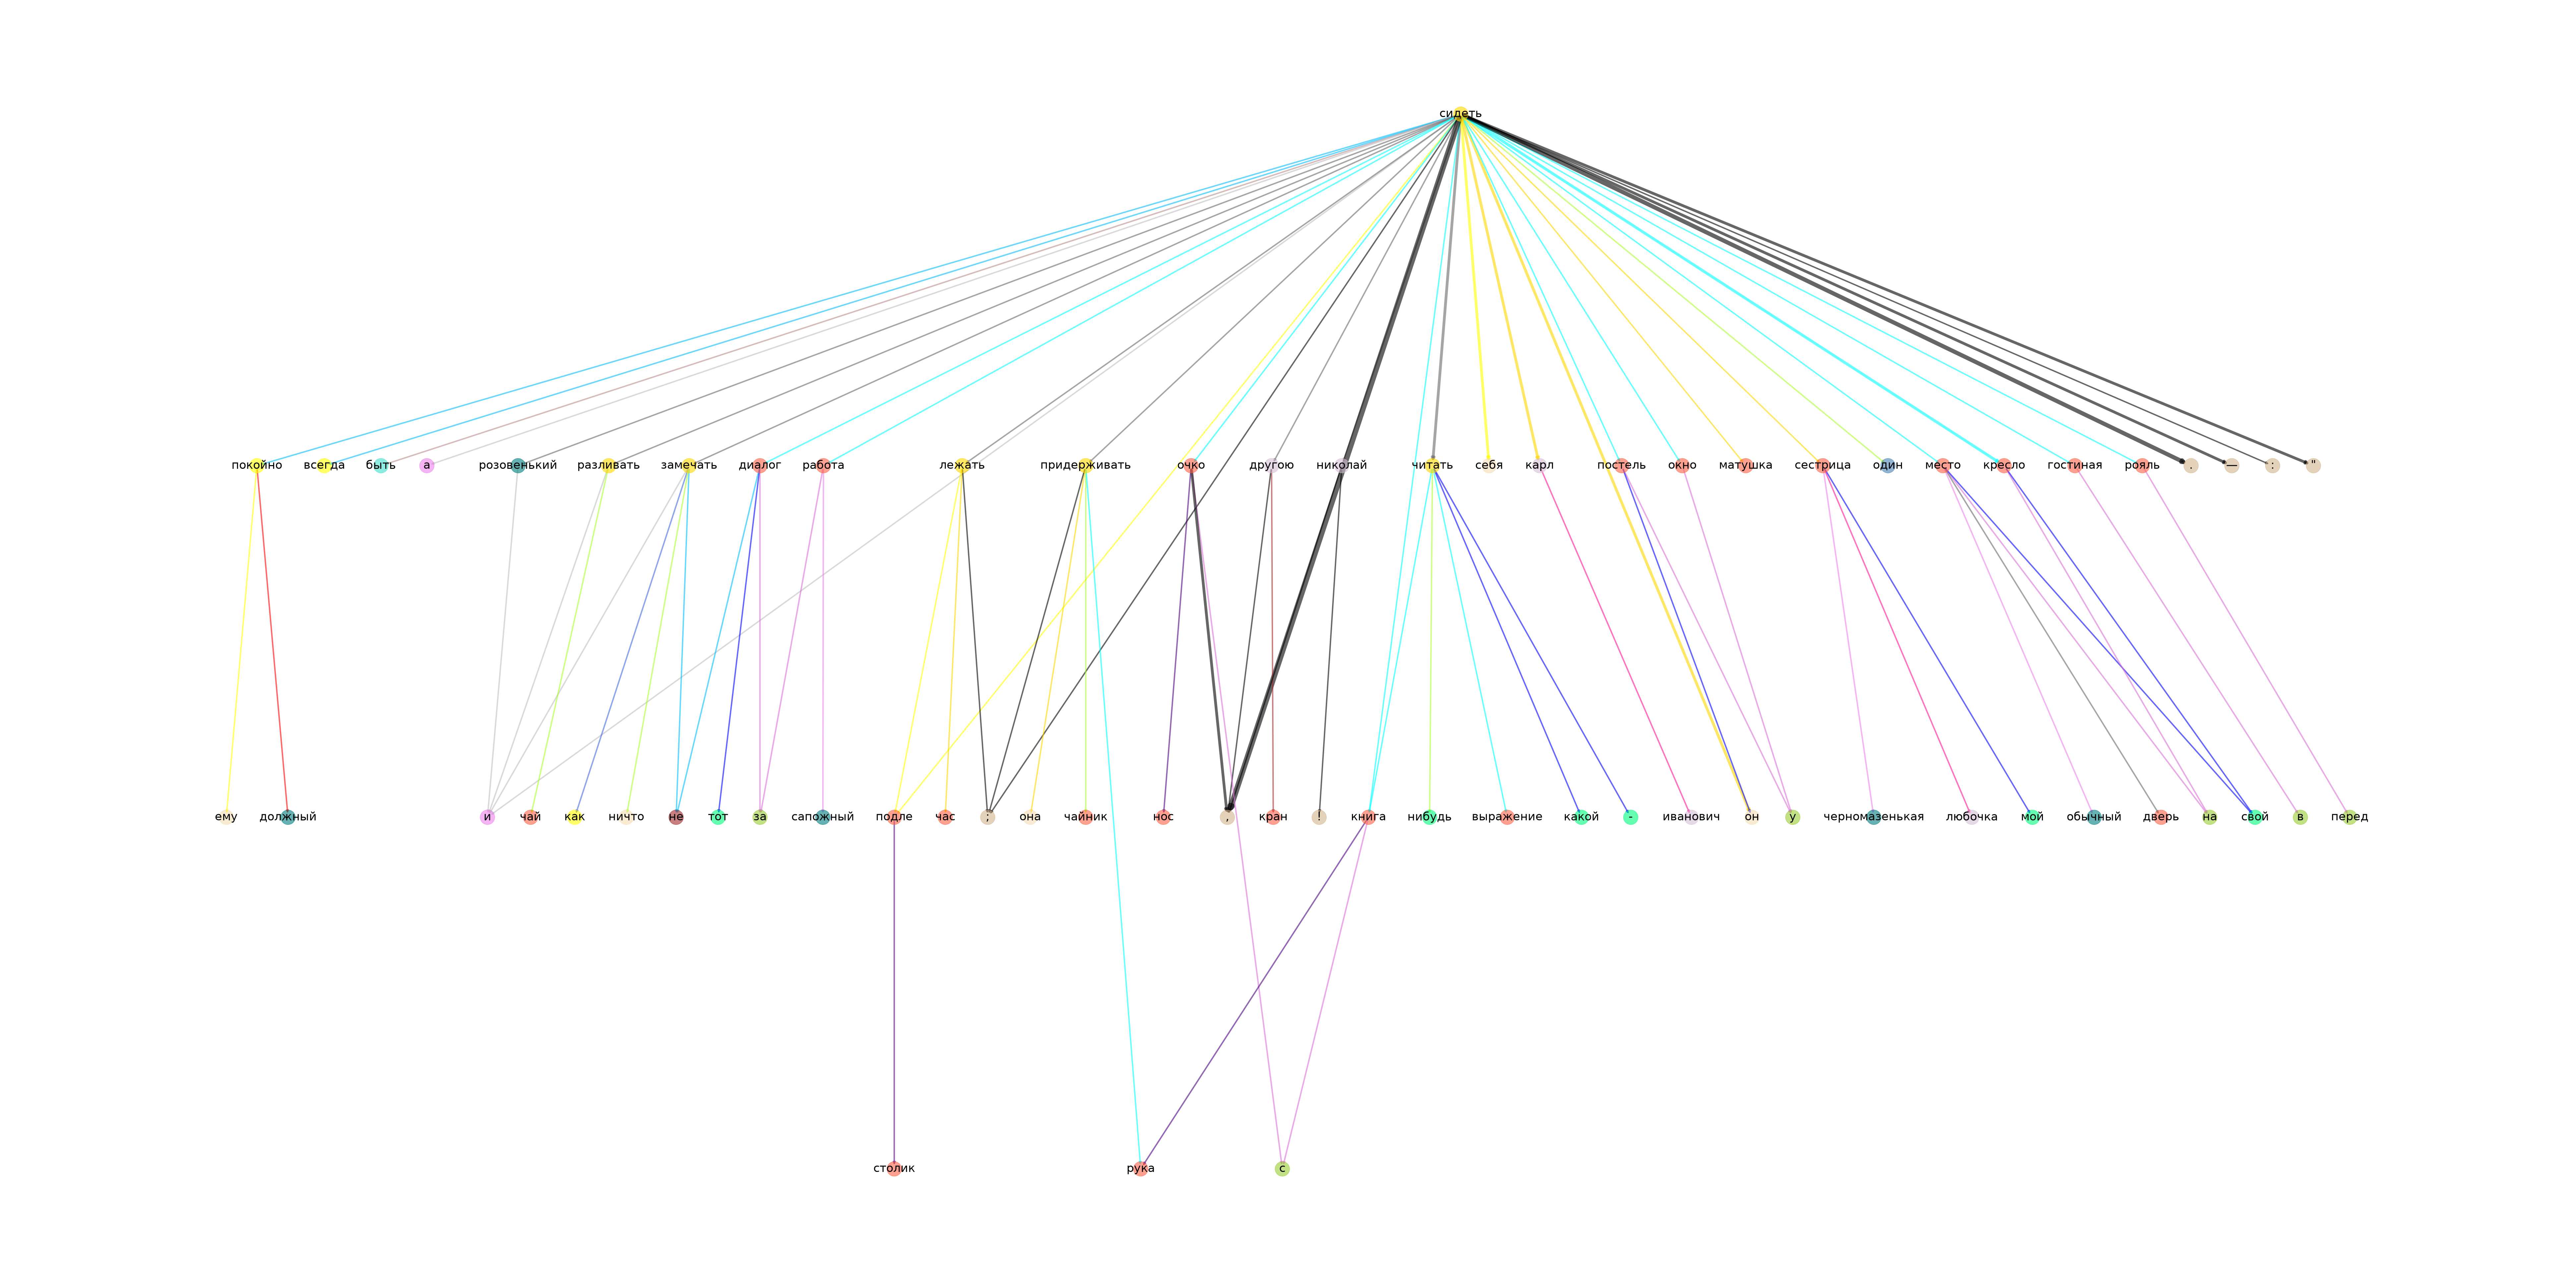

In [25]:
fig, ax = plt.subplots(figsize=(100, 50))

DG = nx.DiGraph()

#DG.add_weighted_edges_from([('blue', 'navy', 1), ('blue', 'green', 3), ('blue', 'black', 5), ('blue', 'pink', 2)])
DG.add_weighted_edges_from(graph_data)

pos = nx.nx_agraph.graphviz_layout(DG, prog="dot")
weights = [d['weight'] * 3 for u, v, d in DG.edges(data=True)]
# labels = dict(zip([(u, v) for u, v in DG.edges()], [nx.get_edge_attributes(DG, 'weight')[u, v]['label'] for u, v in DG.edges()]))

nx.draw_networkx_nodes(DG, pos, node_color=nodes_pos, node_size=1000, alpha=0.6)
nx.draw_networkx_edges(DG, pos, edge_color=edges_dependencies, width=weights, alpha=0.6)
#nx.draw_networkx_edge_labels(DG, pos, edge_labels=labels)
nx.draw_networkx_labels(DG, pos, font_size=25, alpha=1)
plt.axis('off')
#plt.savefig("sidet_network.png", dpi=300, bbox_inches="tight")
plt.show()

I can identify the following governing patterns in the graph (the list is not exhaustive):

* often *сидеть* governs the comma and *и*, which might mean that it very often is a part of a coordinating conjunction. It very often governs other verbs, which might indicate either serial verb constructions of participles

* *сидеть* is not often modifyed by an adverb, as there are not a lot of yellow (not to be confused with gold) nodes

* the graph shows what prepositions are used with what nouns in locative phrases; interestingly, *в* is not very frequent. Rather, the action of sitting is described in relation to the vertical axis of some kind of an object *подле столика, у постели, у окна*, etc.

# Perform network analysis of the graph. Mesure the density, split the graph into communities etc. Describe and justify what and why you are doing.

## Density of the graph

From the linguistic point of view, density in this graph will show to what extend the lemmas may be found in both a primary and a secondary dependency of *сидеть*

In [18]:
print(nx.density(DG))

0.018012422360248446


In this graph, density is very low. This is somehow expected because of the governing patterns of *сидеть*.

However, there are rare examples in which a word may occur in both the primary and the secondary dependency: *и*, *рука*

## Degree centrality

This method will show the nodes with the most relations.

In [27]:
deg = nx.degree_centrality(DG)
for nodeid in sorted(deg, key=deg.get, reverse=True)[:10]:
    print(nodeid)

сидеть
читать
замечать
придерживать
место
и
лежать
сестрица
очко
книга


The results are not surprising. I will comment on the top 3. The node with the most relations is *сидеть* for obious reasons. Then, *читать* may govern a variety of words, including *выражение*, metaphorically. *Замечать* may govern a dependent clause introduced by *как* or an object, be in a conjuction construction or be negated. 

## Communities

By identifying communities, one might find lemmas that are somehow semantically similar.

In [20]:
communities_generator = community.greedy_modularity_communities(DG) # takes out one by one edges with highest betweenness centrality
top_level_communities = communities_generator[0]
next_level_communities = communities_generator[1]
third_level_communities = communities_generator[2]
forth_level_communities = communities_generator[3]
fifth_level_communities = communities_generator[4]
sixth_level_communities = communities_generator[5]

print("top level communities:", top_level_communities)
print("next level communities:", next_level_communities)
print("third level communities:", third_level_communities)
print("forth level communities:", forth_level_communities)
print("fifth level communities:", fifth_level_communities)
print("sixth level communities:", sixth_level_communities)

top level communities: frozenset({'матушка', 'всегда', 'окно', '"', 'один', 'у', 'он', 'себя', 'быть', ':', '.', '—', 'постель', 'а', 'сидеть'})
next level communities: frozenset({'нос', 'читать', 'с', '-', 'нибудь', 'очко', 'какой', 'выражение', 'рука', 'книга'})
third level communities: frozenset({'подле', 'столик', 'лежать', 'придерживать', 'она', ';', 'чайник', 'час'})
forth level communities: frozenset({'чай', 'ничто', 'разливать', 'замечать', 'розовенький', 'как', 'и'})
fifth level communities: frozenset({'кресло', 'свой', 'на', 'дверь', 'место', 'обычный'})
sixth level communities: frozenset({'сапожный', 'диалог', 'тот', 'работа', 'за', 'не'})


I will comment on the top 2 communities. The first community might indicate parts of text connected to domesticity, or the author's own room. The second one seems to be topically related to reading: there are glasses, that are presumable on the nose, and a book, and a hand, which might hold it.

# Could you draw any meaningful conclusions from your analysis? Provide a short (a couple of sentences) answer.

Overall, network analysis has proven itself useful for visualizing and discovering governing patterns of the verb *сидеть*. The observed patterns have been mentioned above. 

However, because I chose a rather semantically neutral word, quantitative network analysis was not particularly useful. Had I chosen a more topically changed word, like *book*, for example, I would find more interpretable communities and more interesting findings of centrality. Moreover, I think that plotting possible syntactic heads alongside dependents of the target word would give more interesting results.